# Which design to recommend: y × C(x) or improvement × C(x)?

`BayesianOptimizer.recommended()` picks, among the evaluated designs, the one that maximises

$$\text{improvement rule:}\quad \max(y - y_{\text{worst}},\, 0)\cdot C(x), \qquad y_{\text{worst}} = \text{lowest feasible } y \text{ observed}$$

This notebook shows what would happen with two simpler rules:

$$\text{raw rule:}\quad y \cdot C(x) \qquad\qquad \text{sign-corrected raw rule:}\quad \begin{cases} y \cdot C(x) & y \ge 0 \\ y \,/\, C(x) & y < 0 \end{cases}$$

The sign-corrected rule keeps the idea of y × C but flips the direction when $y < 0$, so that a higher score always helps. Unlike the improvement rule, the value of a design depends only on its own $y$ and $C$, not on the other evaluated designs.

The objective is **maximised** (here $y = -\text{Rosenbrock} \le 0$, as in the demos), and $C(x) \in [0, 1]$ is the soft-Copeland score learned from a decision maker's comparisons. No BO loop is needed: the rules only need some evaluated designs and their scores, so 40 Sobol designs stand in for the evaluations of a run.

In [1]:
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

for folder in (Path.cwd(), Path.cwd().parent):          # find the package next to or above this notebook
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        break

from BOproj.benchmarks import ROSEN_BOUNDS, PairwiseLabeler, neg_rosenbrock, u_polynomial
from BOproj.bo_loop import initial_design
from BOproj.copeland import SoftCopeland
from BOproj.gp import PreferenceGP

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12})

## The three rules

In [2]:
def improvement_rule(y, scores):
    # what recommended() maximises: improvement over the worst observed y, times the score
    return np.maximum(y - y.min(), 0) * scores


def raw_rule(y, scores):
    # the alternative: the objective value itself, times the score
    return y * scores


def sign_corrected_rule(y, scores):
    # y * C for y >= 0, y / C for y < 0: a higher score always helps; a score of 0 sends y < 0 to -infinity
    with np.errstate(divide="ignore"):
        return np.where(y >= 0, y * scores, y / scores)


RULES = {"raw: y × C": raw_rule,
         "sign-corrected: y × C (y ≥ 0), y / C (y < 0)": sign_corrected_rule,
         "improvement: max(y − worst y, 0) × C": improvement_rule}

## 1. The sign problem in three numbers

With $y \le 0$, multiplying by $C < 1$ pulls $y$ **towards 0**, so a lower score makes a design look better.

In [3]:
toy_y = np.array([-1.0, -1.0, -40.0])
toy_scores = np.array([0.9, 0.5, 0.01])
print(f"{'design':>6s} {'y':>7s} {'C':>6s} {'y × C':>8s} {'sign-corrected':>15s} {'(y − worst) × C':>16s}")
for i, (y_value, score) in enumerate(zip(toy_y, toy_scores)):
    print(f"{i:6d} {y_value:7.1f} {score:6.2f} {raw_rule(toy_y, toy_scores)[i]:8.2f} {sign_corrected_rule(toy_y, toy_scores)[i]:15.2f} "
          f"{improvement_rule(toy_y, toy_scores)[i]:16.2f}")
print("\nraw rule picks design", np.argmax(raw_rule(toy_y, toy_scores)), "| sign-corrected picks design",
      np.argmax(sign_corrected_rule(toy_y, toy_scores)), "| improvement rule picks design", np.argmax(improvement_rule(toy_y, toy_scores)))

design       y      C    y × C  sign-corrected  (y − worst) × C
     0    -1.0   0.90    -0.90           -1.11            35.10
     1    -1.0   0.50    -0.50           -2.00            19.50
     2   -40.0   0.01    -0.40        -4000.00             0.00

raw rule picks design 2 | sign-corrected picks design 0 | improvement rule picks design 0


Designs 0 and 1 have the same y, and the DM prefers design 0 (C = 0.9). The raw rule ranks design 1 above it (−0.5 > −0.9), and it **picks** the terrible design 2 (y = −40, C = 0.01), whose product −0.4 is the largest. The sign-corrected rule (−1.11, −2.00, −4000) and the improvement rule both pick design 0.

## 2. A learned Copeland score on Rosenbrock

The DM prefers designs with small $x_1$ (the `u_polynomial` utility of the benchmarks) and answers 30 comparisons without noise; the score is the soft-Copeland score over 64 landmarks, exactly as in a Copeland run.

In [4]:
X_pref = initial_design(ROSEN_BOUNDS, 30, "lhs", seed=7)
rng = np.random.default_rng(0)
first = rng.integers(0, 30, 30)
second = (first + rng.integers(1, 30, 30)) % 30
decision_maker = PairwiseLabeler(u_polynomial)
preference_gp = PreferenceGP(bounds=ROSEN_BOUNDS, link="probit").fit(
    X_pref[first], X_pref[second], decision_maker(X_pref[first], X_pref[second]))
copeland = SoftCopeland(preference_gp, initial_design(ROSEN_BOUNDS, 64, "random", seed=0)).prepare()


def copeland_score(X):
    with torch.no_grad():
        return copeland(np.atleast_2d(X)).numpy()


X_eval = initial_design(ROSEN_BOUNDS, 40, "sobol", seed=1)   # stand-in for the evaluations of a run
y_eval = neg_rosenbrock(X_eval)
scores_eval = copeland_score(X_eval)
print(f"y from {y_eval.min():.0f} to {y_eval.max():.1f};  C from {scores_eval.min():.2f} to {scores_eval.max():.2f}")

y from -2103 to -2.6;  C from 0.16 to 0.87


### Which design each rule picks

Each dot is an evaluated design, placed by its score and its value. The lines are where each rule is constant: for the raw rule they are hyperbolas $y \cdot C = \text{const}$, and with $y < 0$ they rise towards $C = 0$.

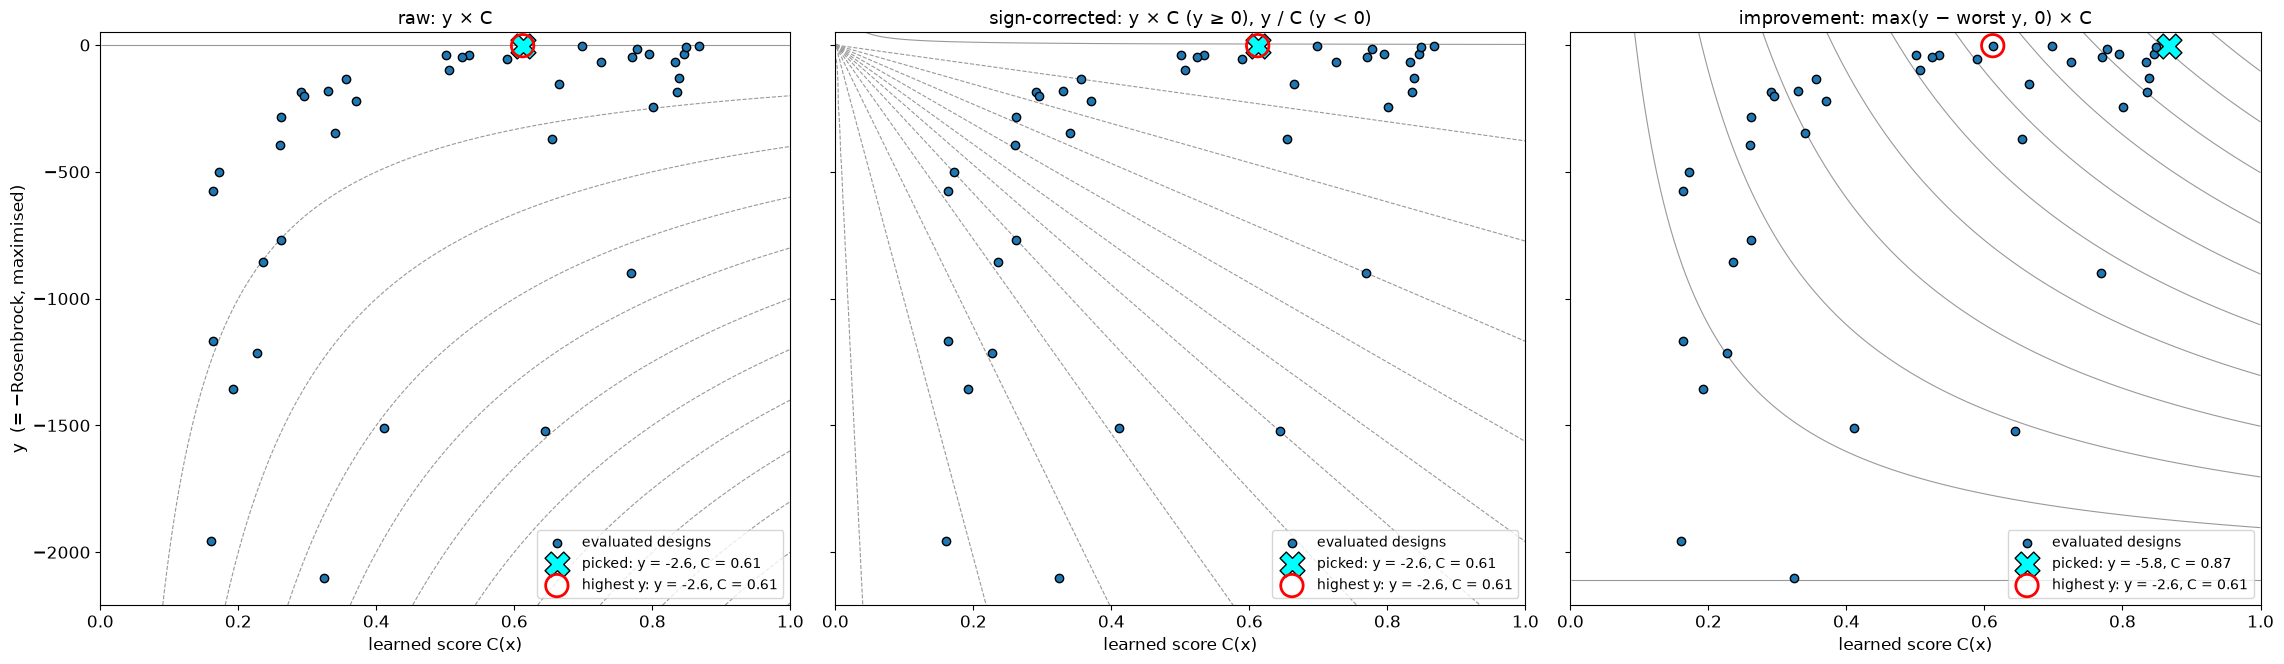

In [5]:
def rule_lines(axis, rule, y_values, reference_y):
    # contour lines of the rule in the (C, y) plane
    C_line, y_line = np.meshgrid(np.linspace(0.001, 1, 300), np.linspace(y_values.min() * 1.05, max(y_values.max(), 0) + 50, 300))
    if rule is raw_rule:
        values = y_line * C_line
    elif rule is sign_corrected_rule:
        values = sign_corrected_rule(y_line, C_line)
    else:
        values = np.maximum(y_line - reference_y.min(), 0) * C_line
    levels = np.unique(np.percentile(values, np.linspace(2, 98, 12))) if rule is sign_corrected_rule else 12     # y / C spans orders of magnitude
    axis.contour(C_line, y_line, values, levels=levels, colors="0.6", linewidths=0.8)


fig, axes = plt.subplots(1, 3, figsize=(23, 6.8), sharey=True)
for axis, (name, rule) in zip(axes, RULES.items()):
    rule_lines(axis, rule, y_eval, y_eval)
    pick = np.argmax(rule(y_eval, scores_eval))
    axis.scatter(scores_eval, y_eval, color="tab:blue", edgecolors="k", zorder=3, label="evaluated designs")
    axis.scatter(scores_eval[pick], y_eval[pick], marker="X", s=320, color="cyan", edgecolors="k", zorder=4,
                 label=f"picked: y = {y_eval[pick]:.1f}, C = {scores_eval[pick]:.2f}")
    best = np.argmax(y_eval)
    axis.scatter(scores_eval[best], y_eval[best], s=260, facecolors="none", edgecolors="red", linewidths=2, zorder=4,
                 label=f"highest y: y = {y_eval[best]:.1f}, C = {scores_eval[best]:.2f}")
    axis.set(xlabel="learned score C(x)", title=name, xlim=(0, 1))
    axis.legend(fontsize=10, loc="lower right")
axes[0].set_ylabel("y  (= −Rosenbrock, maximised)")
plt.tight_layout()
plt.show()

With these designs the raw rule picks the highest y (−2.6): with y that close to 0, y × C is close to 0 whatever C is, so the DM's score hardly matters, and where it matters it counts backwards (a lower C brings the product closer to 0). The improvement rule gives up about 3 units of y for a design the DM likes much more (C = 0.87 against 0.61).

The sign-corrected rule also picks the highest y here. Its contour lines are rays from the origin: it ranks designs by $y / C$, and with $y$ spread over thousands of units and $C$ only between 0.16 and 0.87, $y$ decides almost everything. It fixes the direction of the score, not the balance between $y$ and $C$, which stays set by the units of $y$.

## 3. Adding a constant to y

Maximising $f$ and maximising $f + s$ are the same problem, so the recommendation should not depend on $s$. The improvement rule never does: $y - y_{\text{worst}}$ is unchanged by a shift. The raw rule does. Below, $s$ goes from 0 (all $y \le 0$) to well above the largest $|y|$ (all $y > 0$).

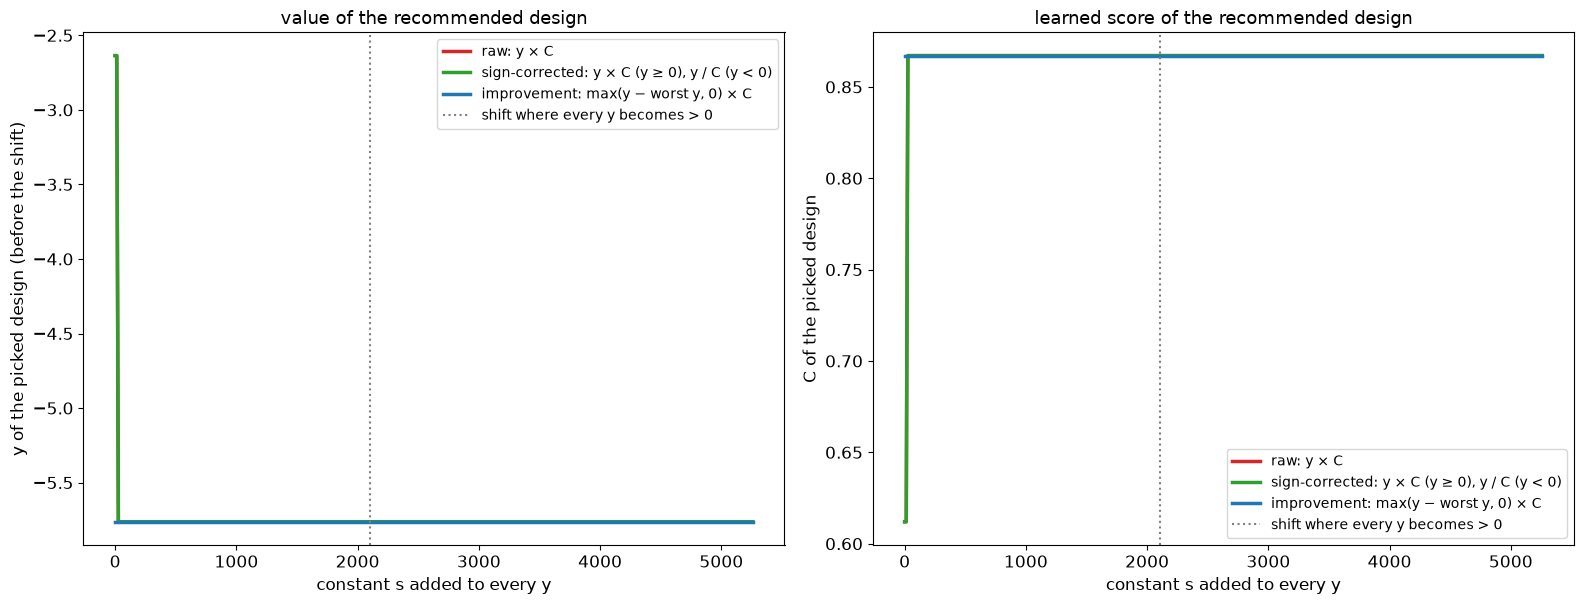

raw: y × C                               picks 2 different design(s) as s varies
sign-corrected: y × C (y ≥ 0), y / C (y < 0) picks 2 different design(s) as s varies
improvement: max(y − worst y, 0) × C     picks 1 different design(s) as s varies


In [6]:
shifts = np.linspace(0, 2.5 * abs(y_eval.min()), 400)
picks = {name: np.array([np.argmax(rule(y_eval + shift, scores_eval)) for shift in shifts]) for name, rule in RULES.items()}

fig, (y_axis, score_axis) = plt.subplots(1, 2, figsize=(16, 6.2))
for (name, chosen), color in zip(picks.items(), ("tab:red", "tab:green", "tab:blue")):
    y_axis.plot(shifts, y_eval[chosen], color=color, lw=2.5, label=name)
    score_axis.plot(shifts, scores_eval[chosen], color=color, lw=2.5, label=name)
for axis in (y_axis, score_axis):
    axis.axvline(abs(y_eval.min()), color="0.5", ls=":", label="shift where every y becomes > 0")
    axis.set_xlabel("constant s added to every y")
    axis.legend(fontsize=10)
y_axis.set(ylabel="y of the picked design (before the shift)", title="value of the recommended design")
score_axis.set(ylabel="C of the picked design", title="learned score of the recommended design")
plt.tight_layout()
plt.show()
for name, chosen in picks.items():
    print(f"{name:40s} picks {len(np.unique(chosen))} different design(s) as s varies")

Here the raw rule and the sign-corrected rule each change their pick once, at a small shift, and from then on agree with the improvement rule: once every $y$ is positive, both are simply $y \cdot C$, and the improvement rule picks the same design. That is no coincidence for the improvement rule either: for the evaluated designs it **is** the raw rule after the shift $s = -(\text{worst } y)$, which moves the zero of $y$ to the worst observation. The raw and sign-corrected rules leave that choice of zero to whatever the objective's units happen to be.

## 4. The rules over the whole box

The same rules applied to every design of a grid, with the true f, as the last cell of `copeland_demo.ipynb` does (yellow = high). With y ≤ 0 the raw product can never exceed 0, and it reaches 0 wherever y = 0, whatever C is: its maximum sits on the optimum of Rosenbrock, which the DM scores poorly. The improvement map peaks where the DM's score is high and y is still good.

The sign-corrected map has the same problem as the raw one in a different form: with $y \le 0$ it is largest where $y$ is closest to 0, so its maximum also sits on the Rosenbrock optimum, whatever the DM's score is there. Its colours are clipped at the 2nd percentile for display, because $y / C$ reaches −15 000 where $C$ is small.

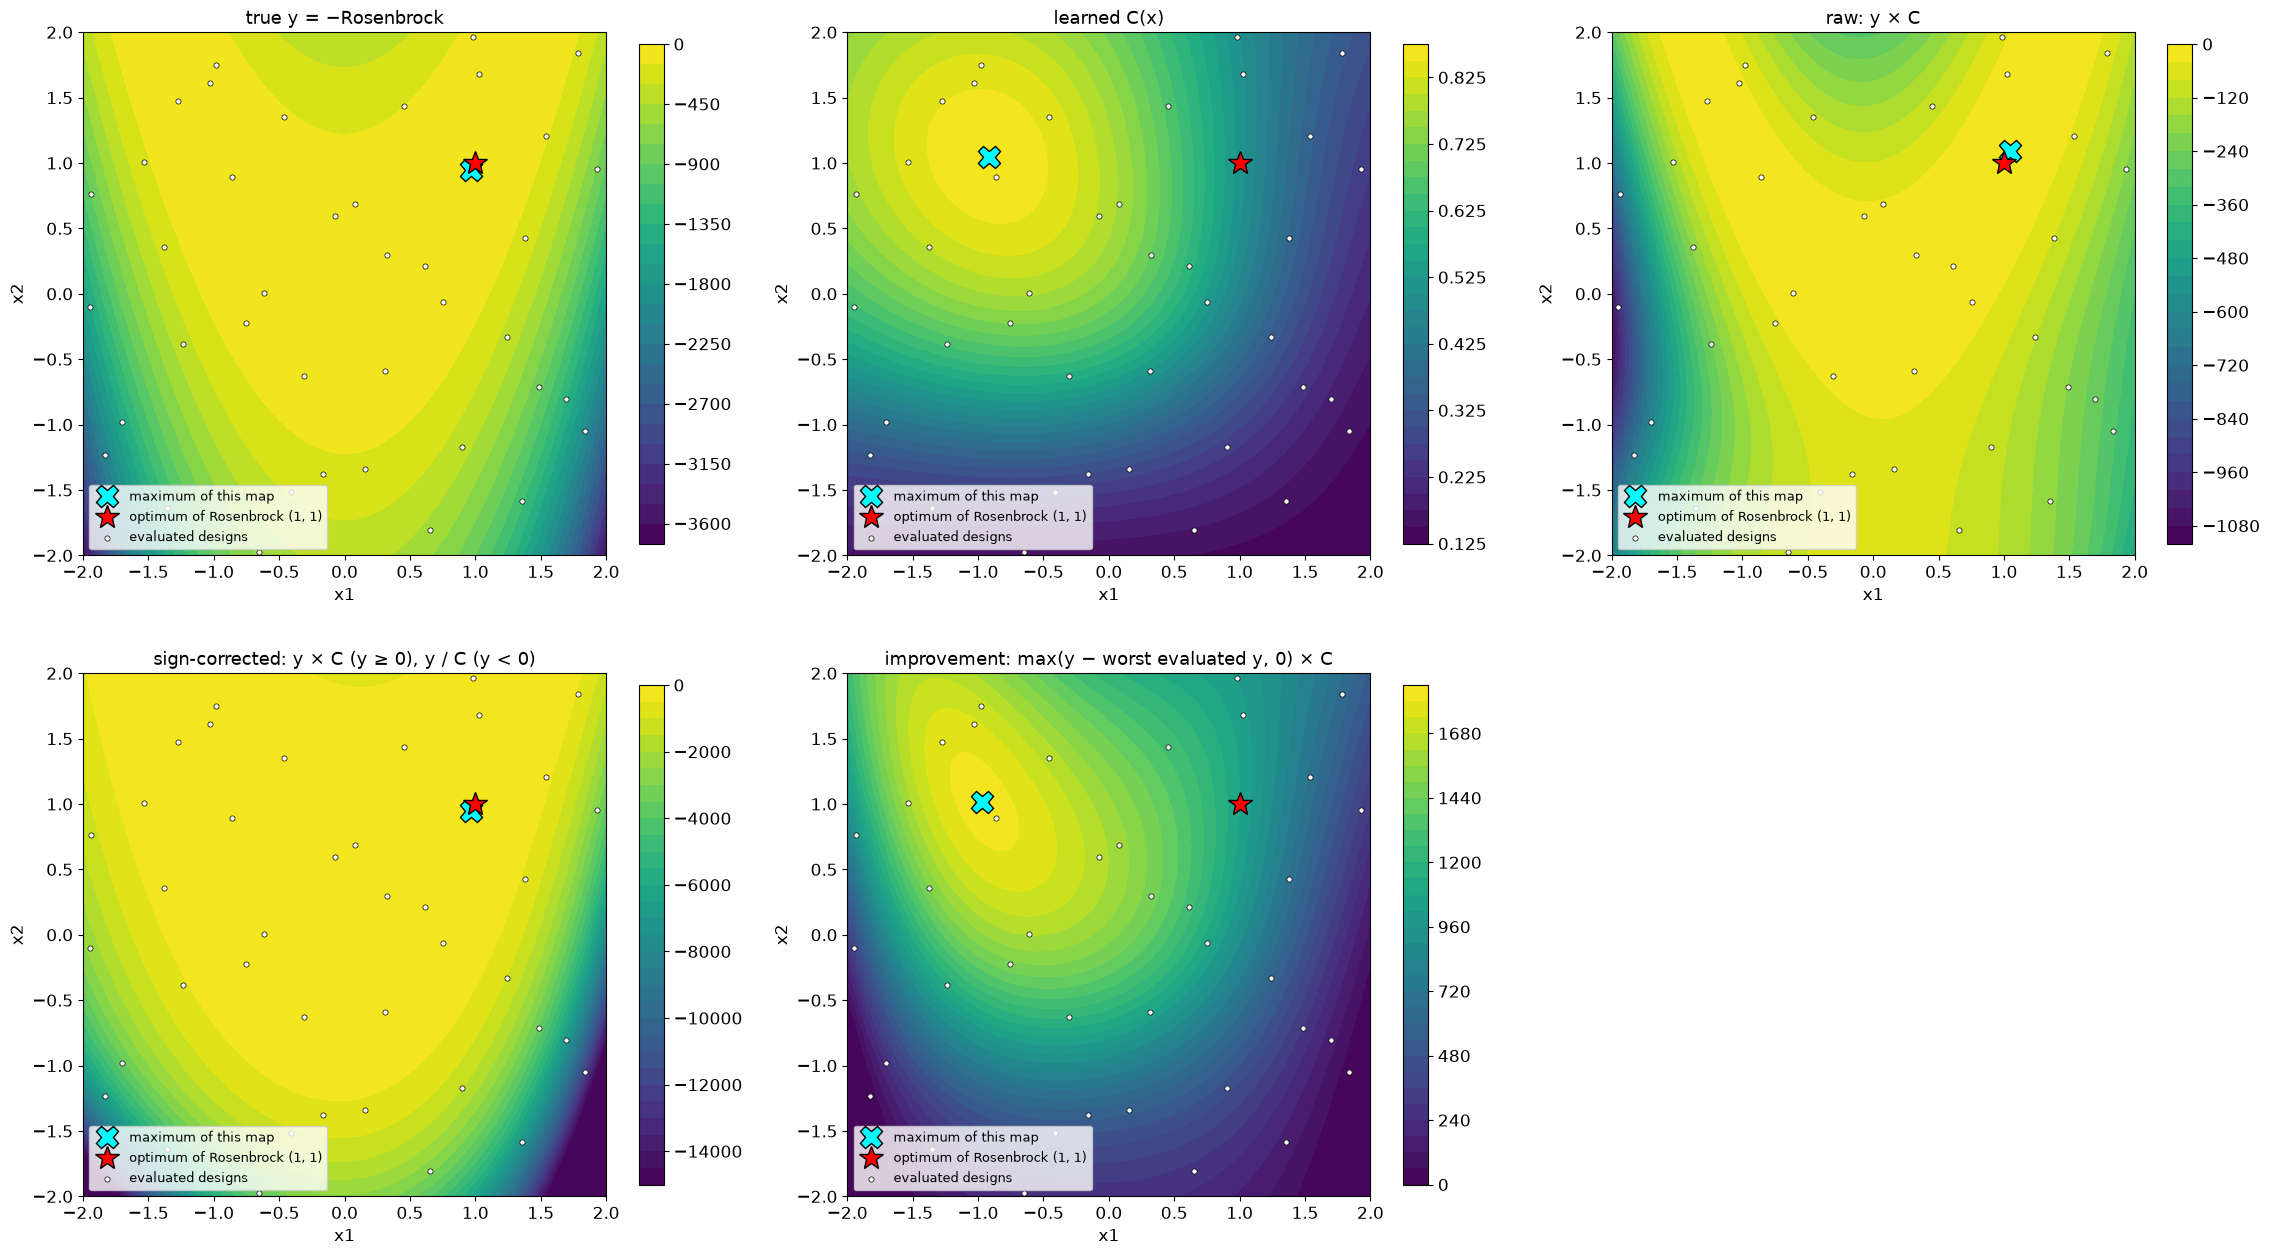

In [7]:
grid_1, grid_2 = np.meshgrid(np.linspace(*ROSEN_BOUNDS[0], 160), np.linspace(*ROSEN_BOUNDS[1], 160))
X_grid = np.c_[grid_1.ravel(), grid_2.ravel()]
y_grid, scores_grid = neg_rosenbrock(X_grid), copeland_score(X_grid)
maps = {"true y = −Rosenbrock": y_grid, "learned C(x)": scores_grid,
        "raw: y × C": raw_rule(y_grid, scores_grid),
        "sign-corrected: y × C (y ≥ 0), y / C (y < 0)": sign_corrected_rule(y_grid, scores_grid),
        "improvement: max(y − worst evaluated y, 0) × C": np.maximum(y_grid - y_eval.min(), 0) * scores_grid}

fig, axes = plt.subplots(2, 3, figsize=(23, 13))
for axis, (name, values) in zip(axes.ravel(), maps.items()):
    low = np.percentile(values[np.isfinite(values)], 2) if "sign-corrected" in name else values.min()   # y / C is huge where C is small: clip the colours
    shown = axis.contourf(grid_1, grid_2, np.clip(values, low, None).reshape(grid_1.shape), levels=30, cmap="viridis")
    fig.colorbar(shown, ax=axis, shrink=0.85)
    top = np.argmax(values)
    axis.plot(*X_grid[top], "X", ms=16, color="cyan", mec="k", label="maximum of this map")
    axis.plot(1, 1, "*", ms=18, color="red", mec="k", label="optimum of Rosenbrock (1, 1)")
    axis.scatter(*X_eval.T, s=14, color="white", edgecolors="k", linewidths=0.5, label="evaluated designs")
    axis.set(title=name, xlabel="x1", ylabel="x2", aspect="equal")
    axis.legend(fontsize=9, loc="lower left")
for axis in axes.ravel()[len(maps):]:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. The baseline problem: the worst design gets weight 0

The improvement rule measures every design from the **lowest** $y$ of the evaluated set: $w_i = (y_i - y_{\min})\, C_i$. Two consequences:

1. **A design that is the worst so far gets weight 0, whatever its score.** A new design with $y < y_{\min}$ becomes the new $y_{\min}$, so its own weight is $(y - y)\, C = 0$ even if $C = 1$.
2. **A design that never wins can still change the answer.** The new, lower baseline raises every other weight by $(y_{\min}^{\text{old}} - y_{\text{new}})\, C_j$, most for the designs with a high score, so their order can flip.

Example: designs A $(y = -10,\ C = 0.5)$ and B $(y = -12,\ C = 0.9)$, then a poor design D $(y = -50,\ C = 0.95)$ that the DM likes arrives. The sign-corrected rule scores each design by itself and the improvement rule does not.

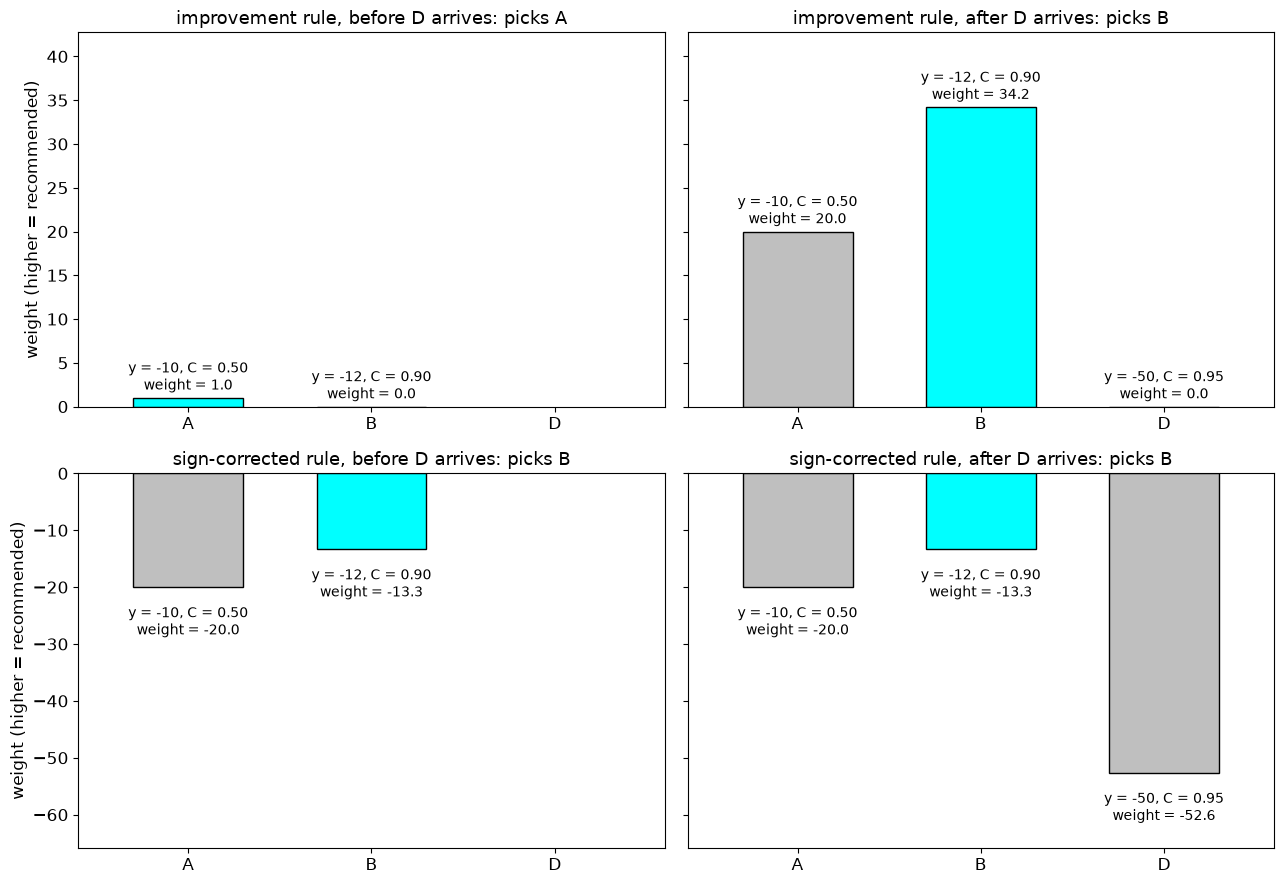

improvement rule     before D arrives  {'A': 1.0, 'B': 0.0} -> picks A
improvement rule     after D arrives   {'A': 20.0, 'B': 34.2, 'D': 0.0} -> picks B
sign-corrected rule  before D arrives  {'A': -20.0, 'B': -13.33} -> picks B
sign-corrected rule  after D arrives   {'A': -20.0, 'B': -13.33, 'D': -52.63} -> picks B


In [8]:
baseline_names = ["A", "B", "D"]
baseline_y = np.array([-10.0, -12.0, -50.0])
baseline_scores = np.array([0.5, 0.9, 0.95])
situations = {"before D arrives": [0, 1], "after D arrives": [0, 1, 2]}
shown_rules = {"improvement rule": improvement_rule, "sign-corrected rule": sign_corrected_rule}

fig, axes = plt.subplots(len(shown_rules), len(situations), figsize=(13, 9), sharey="row")
for row, (rule_name, rule) in zip(axes, shown_rules.items()):
    for axis, (situation, members) in zip(row, situations.items()):
        weights = rule(baseline_y[members], baseline_scores[members])
        pick = members[int(np.argmax(weights))]
        bars = axis.bar(members, weights, color=["cyan" if member == pick else "0.75" for member in members], edgecolor="k", width=0.6)
        for member, weight in zip(members, weights):
            axis.annotate(f"y = {baseline_y[member]:.0f}, C = {baseline_scores[member]:.2f}\nweight = {weight:.1f}", (member, weight),
                          textcoords="offset points", xytext=(0, 6 if weight >= 0 else -34), ha="center", fontsize=10)
        axis.set(xticks=range(3), xticklabels=baseline_names, xlim=(-0.6, 2.6), title=f"{rule_name}, {situation}: picks {baseline_names[pick]}")
        axis.margins(y=0.25)
    row[0].set_ylabel("weight (higher = recommended)")
plt.tight_layout()
plt.show()

for rule_name, rule in shown_rules.items():
    for situation, members in situations.items():
        weights = rule(baseline_y[members], baseline_scores[members])
        print(f"{rule_name:20s} {situation:17s}", {baseline_names[m]: round(float(w), 2) for m, w in zip(members, weights)},
              "-> picks", baseline_names[members[int(np.argmax(weights))]])

## 6. Summary

| property | raw: $y \cdot C$ | sign-corrected: $y \cdot C$ ($y \ge 0$), $y / C$ ($y < 0$) | improvement: $\max(y - y_{\text{worst}}, 0) \cdot C$ |
|---|---|---|---|
| sign of $y$ | with $y < 0$ a lower C looks better | a higher C always helps | a higher C always helps |
| adding a constant to $y$ | changes the recommendation | changes it (the sign flip moves with the zero of y) | no effect |
| multiplying $y$ by a positive constant | no effect | no effect | no effect |
| depends on the other evaluated designs | no | no | **yes**: through the worst $y$ |
| the worst design | can still win (its $y \cdot C$ is small in size) | wins only if its own $y$ and $C$ are good | has weight 0 whatever its score |
| a new, lower-$y$ design | no effect on the others | no effect on the others | moves the baseline: can flip the order of the others |
| what sets the trade-off between y and C | the arbitrary zero of y | the arbitrary zero of y | the worst observed y |
| needs a guard | no | $C = 0$ (division) | all weights 0 (falls back to the highest y) |

The raw rule is only safe for an objective with a positive $y$ and a meaningful zero (a profit, a yield). The improvement rule removes the dependence on the zero of $y$ and fixes the sign, at the cost of depending on the worst observation. The sign-corrected rule fixes the sign and keeps every design's score independent of the others, but still depends on where $y = 0$ is.

In one line: the improvement rule is the raw rule with the zero of $y$ moved to the worst observation, so that every product is $\ge 0$ and a higher score always helps.